# Morpho CAVE/TEASAR confidence sweep: all folds

This analysis reads saved final reports and epoch caches through the frozen report catalog. It produces **equal-weight means across five folds**, with **pointwise 95% Student-t confidence intervals** (four degrees of freedom). Folds, not individual windows, are the uncertainty unit. The training sets overlap across folds, so these intervals describe fold variability; they are not independent-replicate or untouched-test confidence guarantees.

No five-fold summary is drawn for an incomplete group. Learning curves use only epochs present in all five folds. Paired differences are computed within each fold before averaging. Confusion matrices average **row-normalized matrices**, rather than pooling windows; each cell displays its mean and CI half-width. Unsupported class rows are marked rather than treated as zero accuracy.

Whole-cell analyses retain the historical eight-class hierarchy and 5 µm Euclidean nucleus exclusion. Density analyses use **six-class morpho labels at confidence ≥0.7**, with bins 32/16/8/4 and 9/17/33/65 nodes. Historical mesh-skeleton comparisons retain their five neuronal classes. V1DD models select epochs using **MICrONS validation-window macro F1 only**, while preserving separate MICrONS, V1DD, and combined final results. The paired axon/dendrite experiment retains its separate inner validation split; other historical experiments select on the reported held-out fold.

Source analysis: `analysis/presynaptic/morpho_confidence_native/morpho_confidence_comparison.ipynb`. The original version, where present, is archived under `analysis/report_folds_20261012/legacy_notebooks/`. These pages cover the report's registered models; historical mixed-batch pilots are retained in that archive rather than mixed into the report comparison.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
from IPython.display import display
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/train_gnn.py').exists())
sys.path.insert(0,str(root/'analysis/report_folds_20261012'))
import all_folds as af
cache=af.load('Morpho CAVE/TEASAR confidence sweep',family='TEASAR',model=None)
display(cache['status'][['label','completed_folds','complete']])


,label,completed_folds,complete
0,TEASAR / Mean / conf0,"[0, 1, 2, 3, 4]",True
1,TEASAR / Pointwise MLP / conf0,"[0, 1, 2, 3, 4]",True
2,TEASAR / GT / conf0,"[0, 1, 2, 3, 4]",True
3,TEASAR / Mean / conf0.3,"[0, 1, 2, 3, 4]",True
4,TEASAR / Pointwise MLP / conf0.3,"[0, 1, 2, 3, 4]",True
5,TEASAR / GT / conf0.3,"[0, 1, 2, 3, 4]",True
6,TEASAR / Mean / conf0.5,"[0, 1, 2, 3, 4]",True
7,TEASAR / Pointwise MLP / conf0.5,"[0, 1, 2, 3, 4]",True
8,TEASAR / GT / conf0.5,"[0, 1, 2, 3, 4]",True
9,TEASAR / Mean / conf0.7,"[0, 1, 2, 3, 4]",True


## Window and cell performance
Mean across folds with 95% fold confidence intervals.

,label,domain,scope,metric,mean,ci_low,ci_high,folds
0,TEASAR / Mean / conf0,Combined,window,accuracy,0.835540,0.820059,0.851020,5
1,TEASAR / Mean / conf0,Combined,window,balanced_accuracy,0.688403,0.664946,0.711861,5
2,TEASAR / Mean / conf0,Combined,window,macro_precision,0.682520,0.660667,0.704374,5
3,TEASAR / Mean / conf0,Combined,window,macro_f1,0.677273,0.660703,0.693843,5
4,TEASAR / Mean / conf0,Combined,cell,accuracy,0.940378,0.919858,0.960899,5
...,...,...,...,...,...,...,...,...
115,TEASAR / GT / conf0.9,Combined,window,macro_f1,0.694478,0.666837,0.722118,5
116,TEASAR / GT / conf0.9,Combined,cell,accuracy,0.942798,0.929113,0.956482,5
117,TEASAR / GT / conf0.9,Combined,cell,balanced_accuracy,0.780316,0.724954,0.835679,5
118,TEASAR / GT / conf0.9,Combined,cell,macro_precision,0.937461,0.910580,0.964342,5


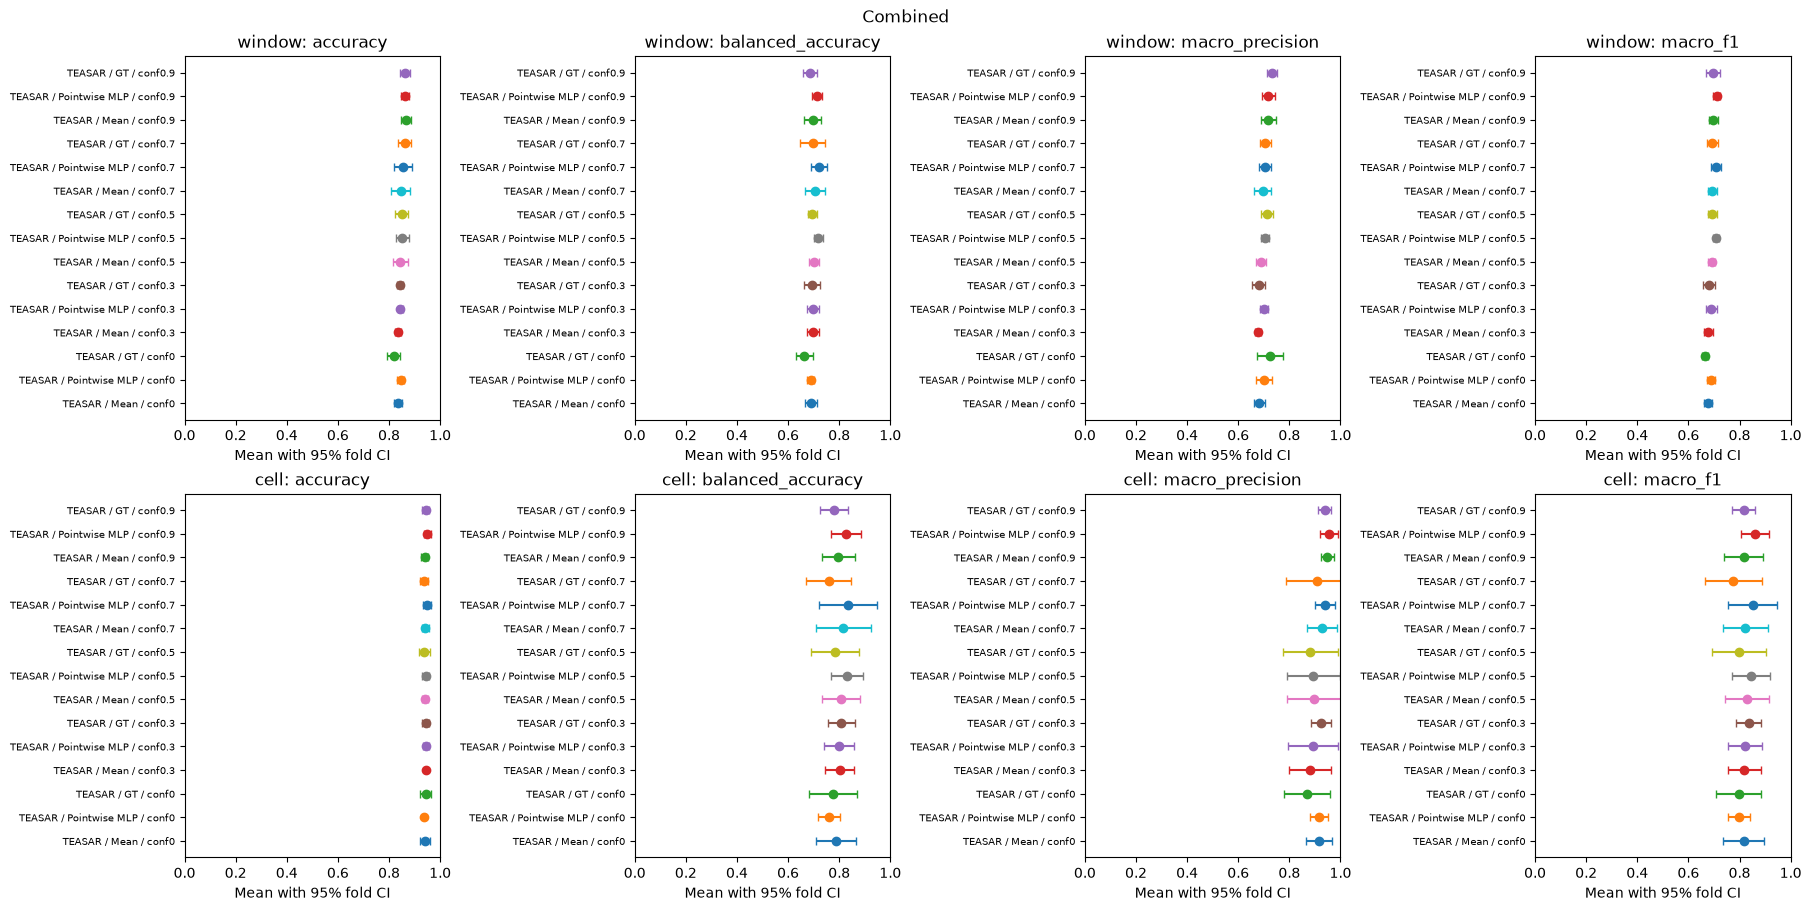

In [2]:
display(af.summary(cache))
af.plot_scores(cache)

## Cohort composition
For confidence sweeps: mean source-manifest cell counts and 95% fold CIs. Entire-cohort counts are identical across folds, so their intervals have zero width. These counts precede window eligibility filtering.

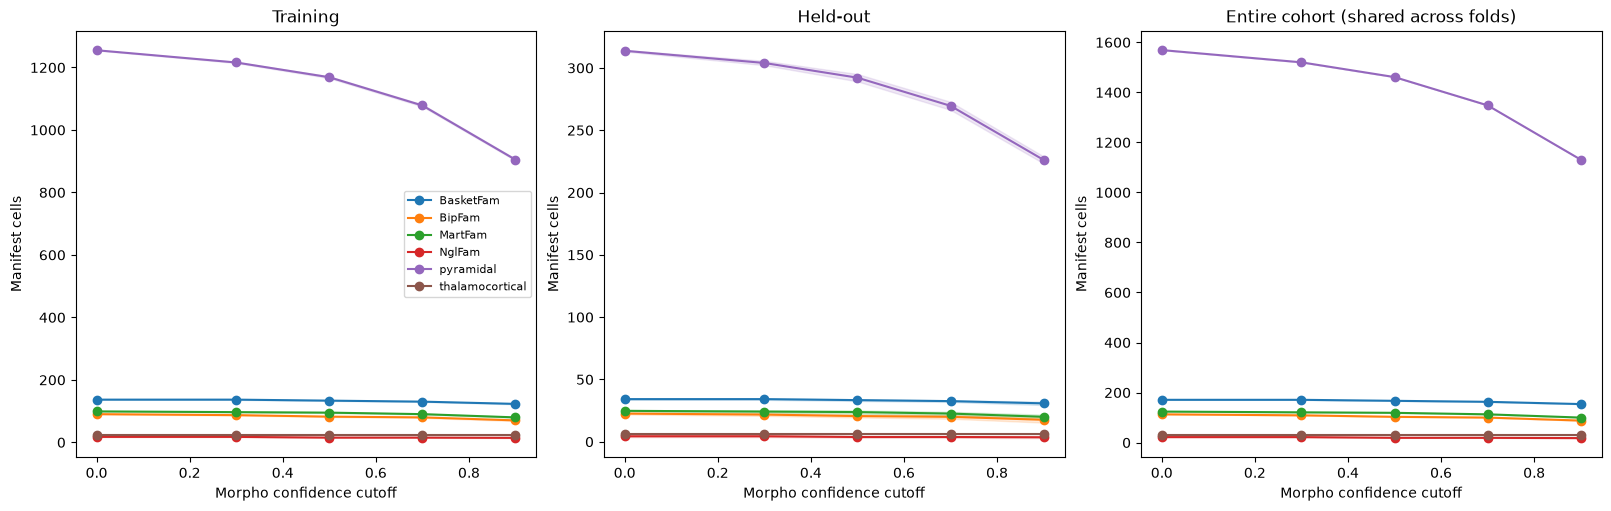

In [3]:
af.plot_cohort_counts(cache)

## Confidence / density trends
Five-fold mean with shaded 95% fold CI, where applicable.

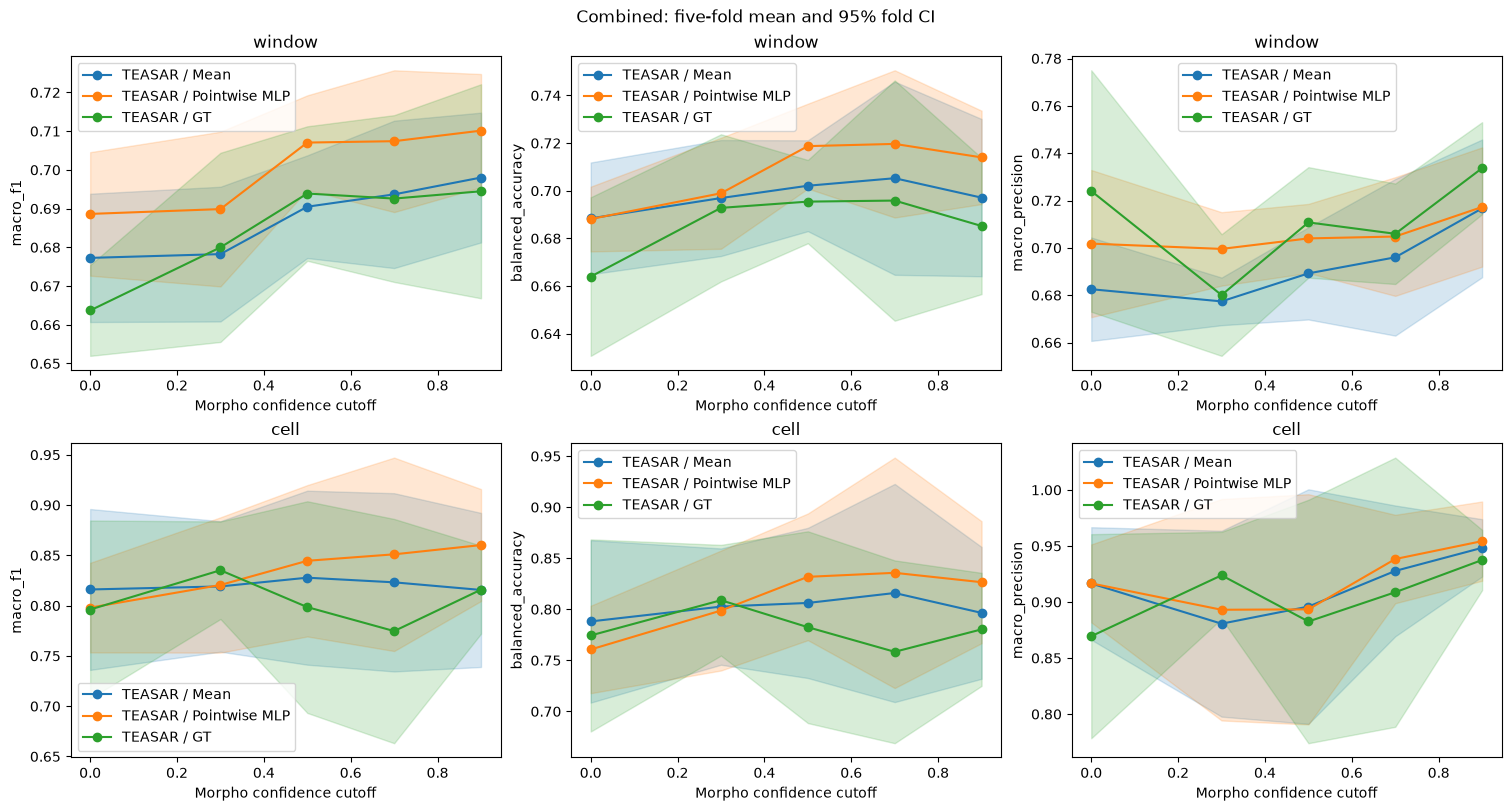

In [4]:
af.plot_trends(cache)

## Training progress
Mean curve and shaded 95% fold CI; no individual-fold overlays.

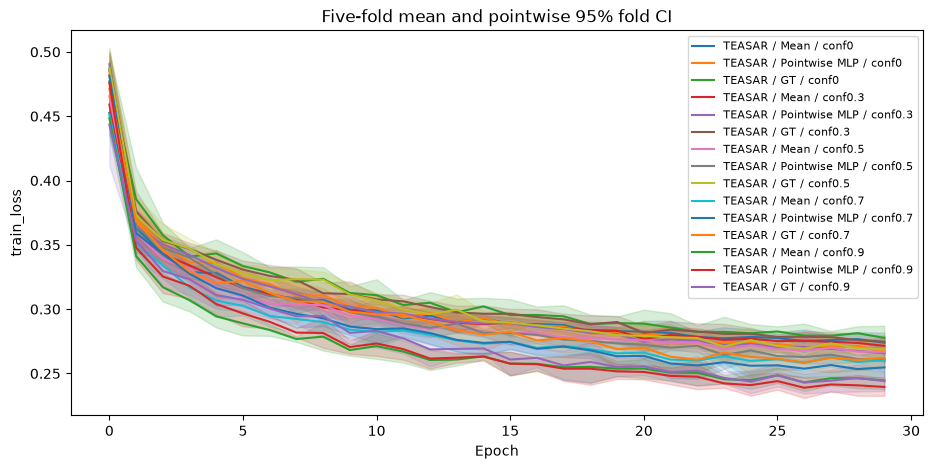

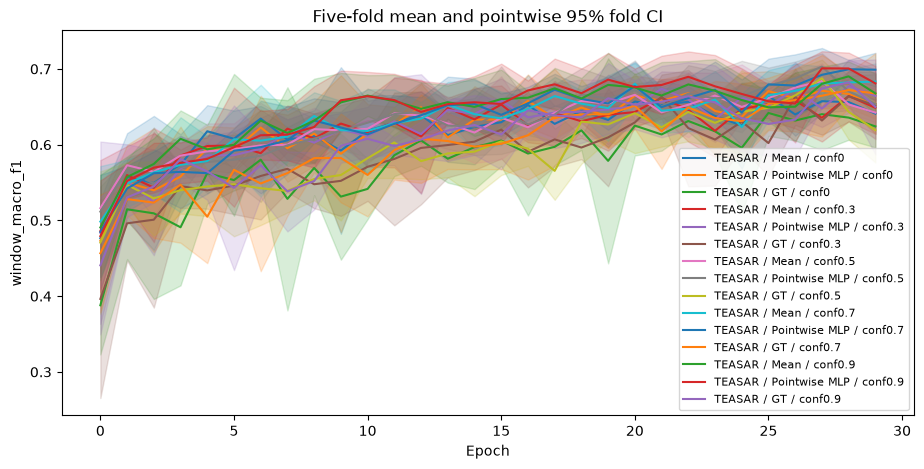

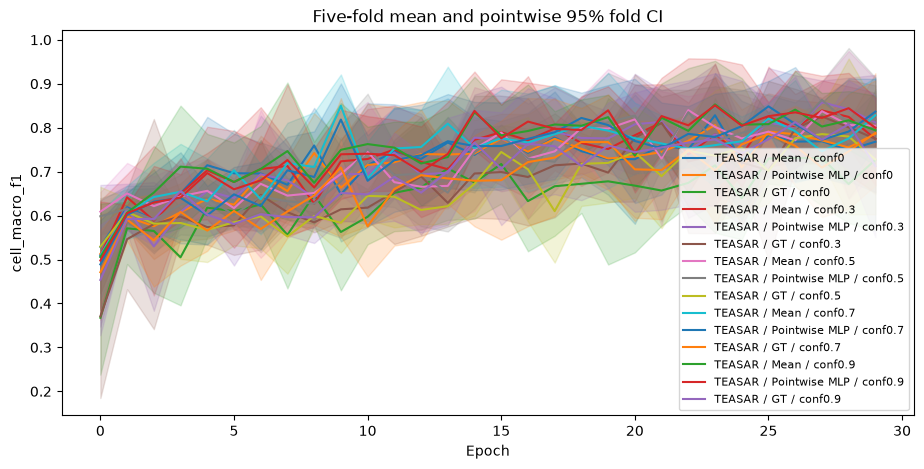

In [5]:
af.plot_curves(cache)

## Paired changes
Within-fold differences with 95% fold CI.

In [6]:
af.plot_deltas(cache)

## Class recall, precision, and support
Means and shaded 95% fold CIs.

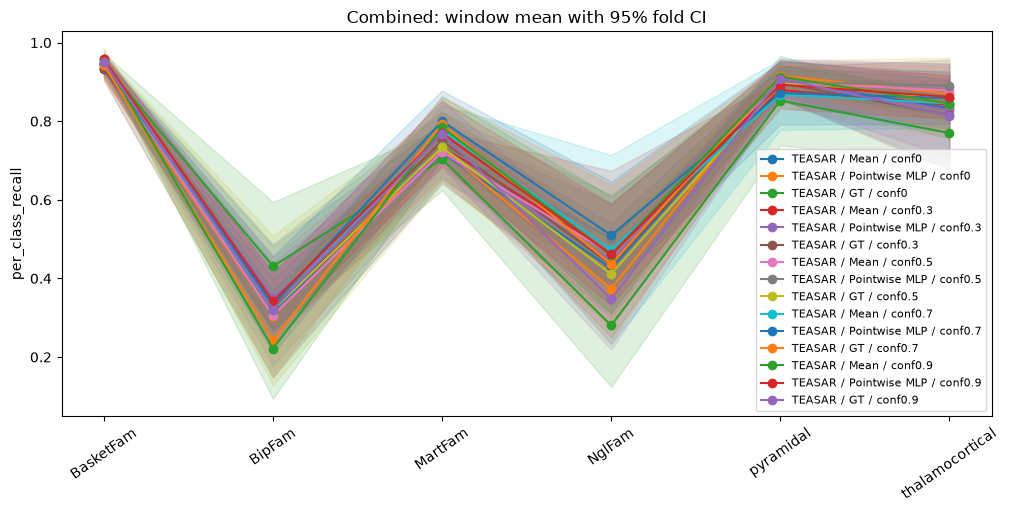

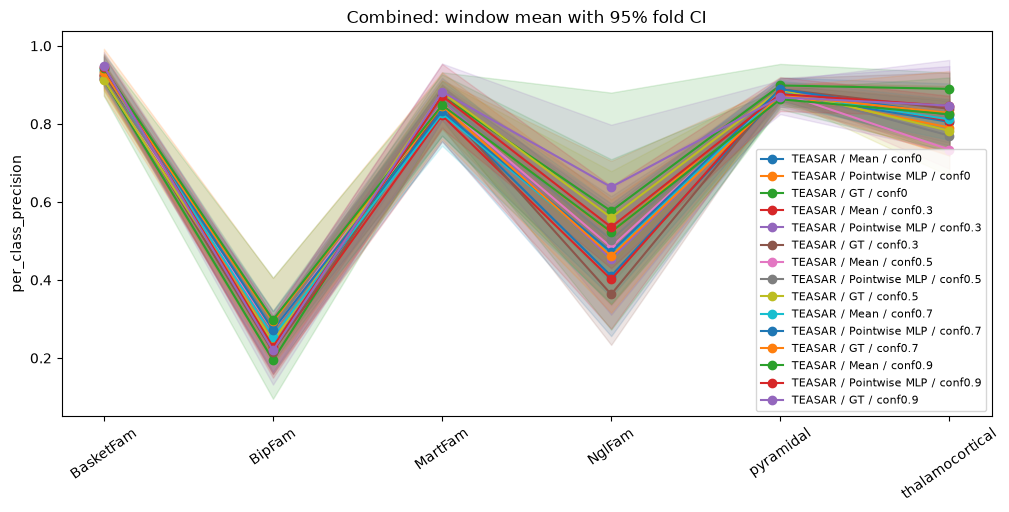

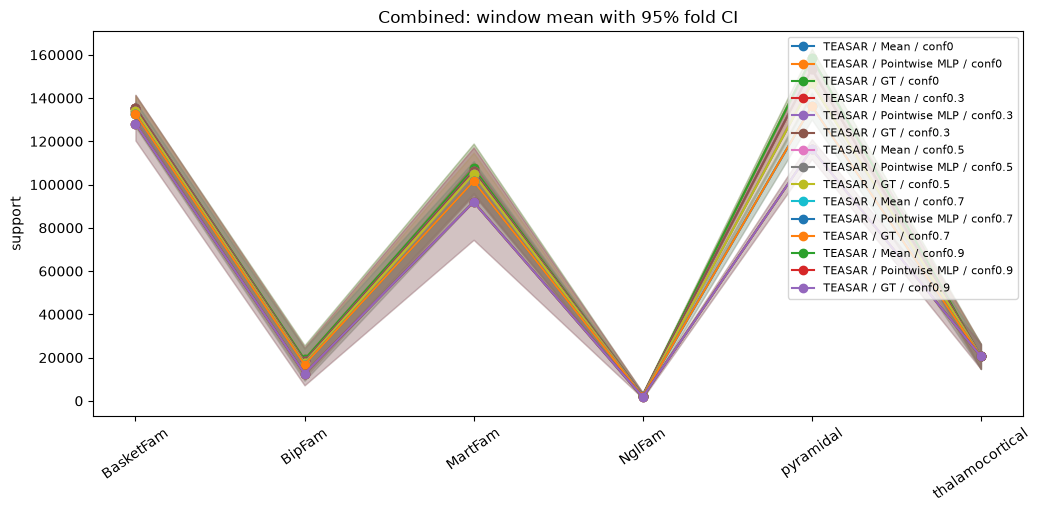

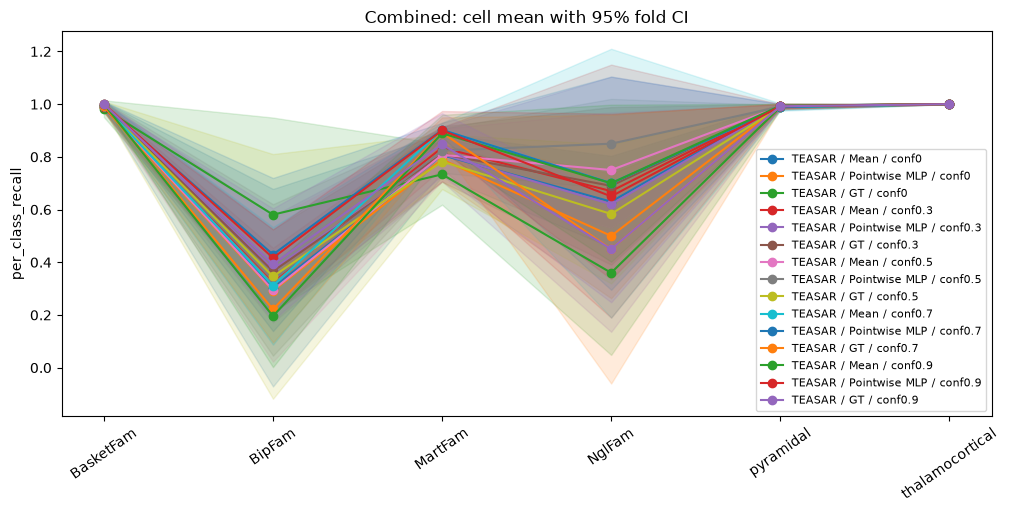

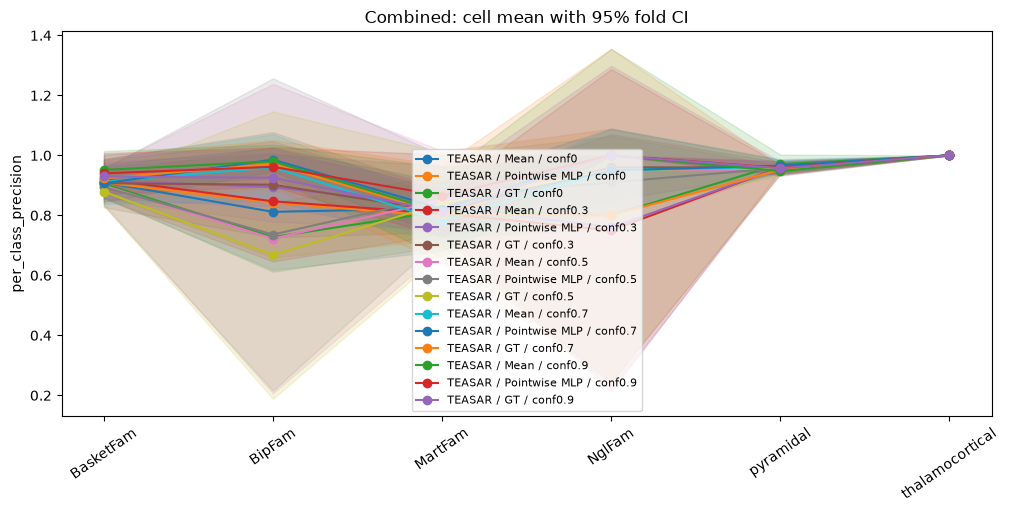

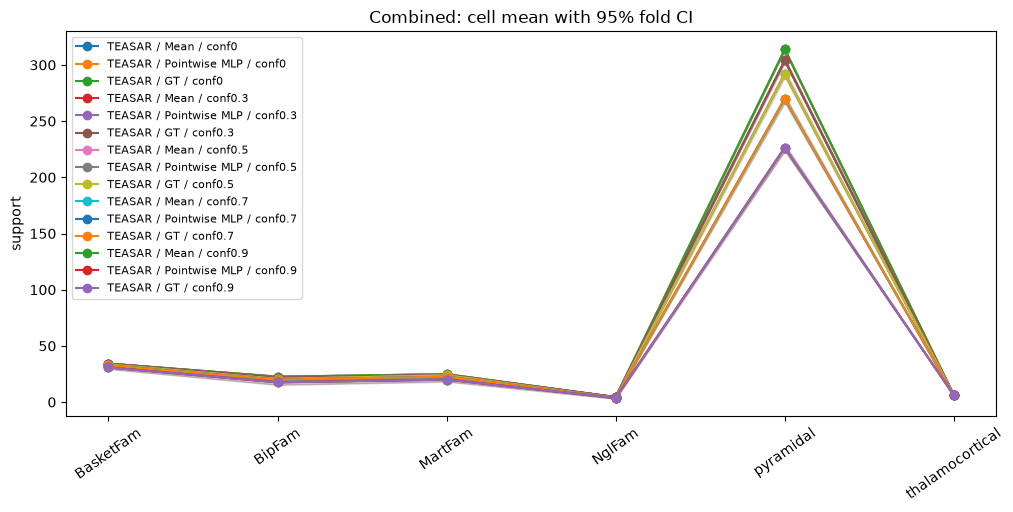

In [7]:
af.plot_classes(cache)

## Confusion matrices
Equal fold-weighted normalized confusion matrices, with 95% fold CI per cell.

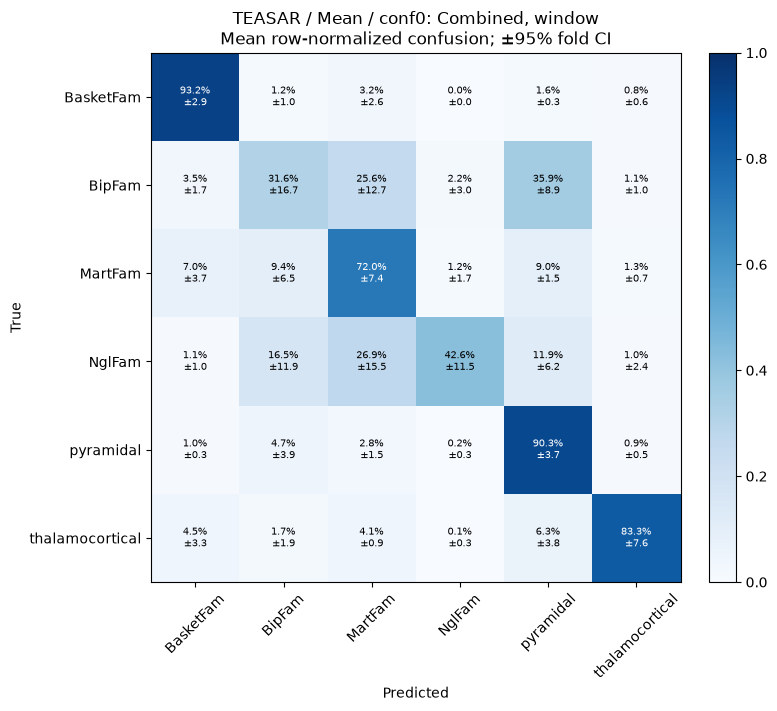

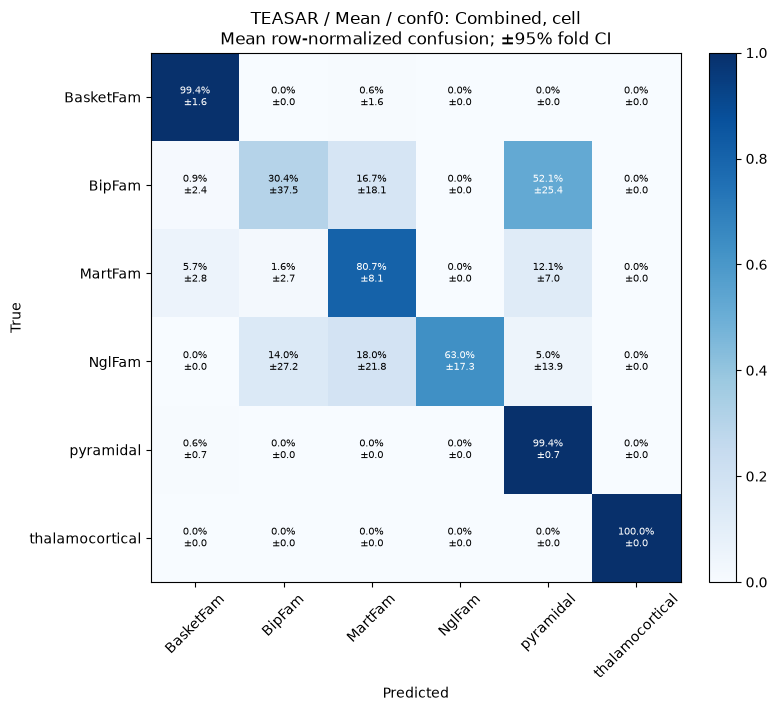

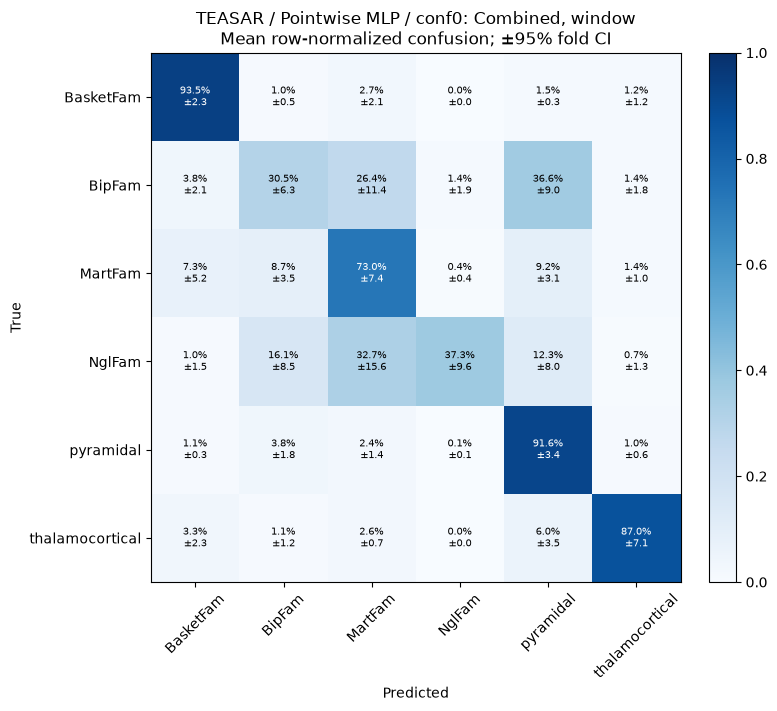

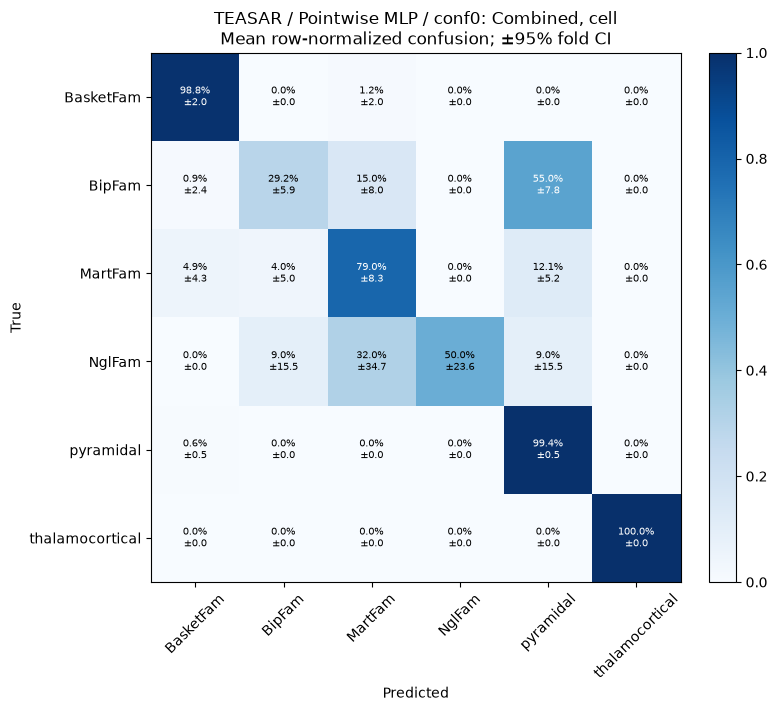

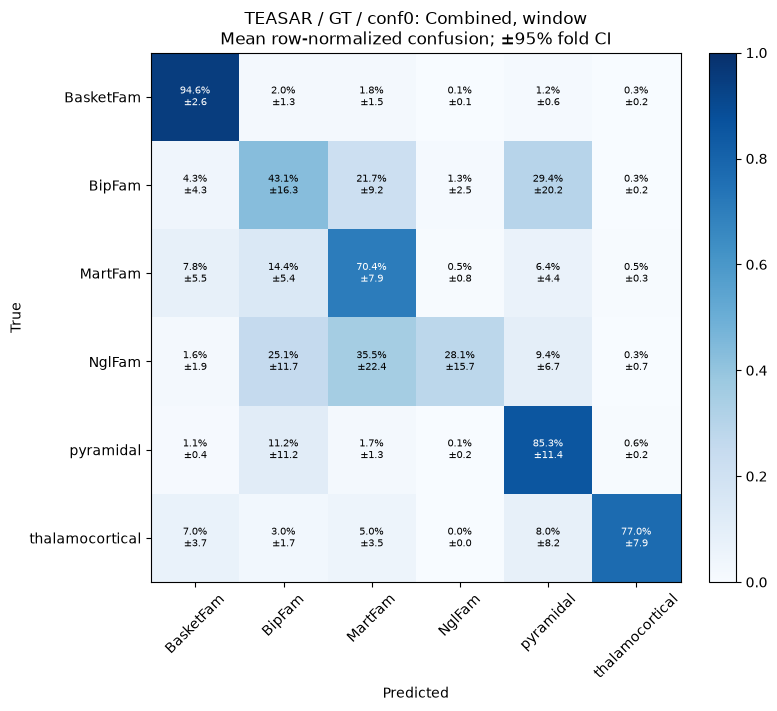

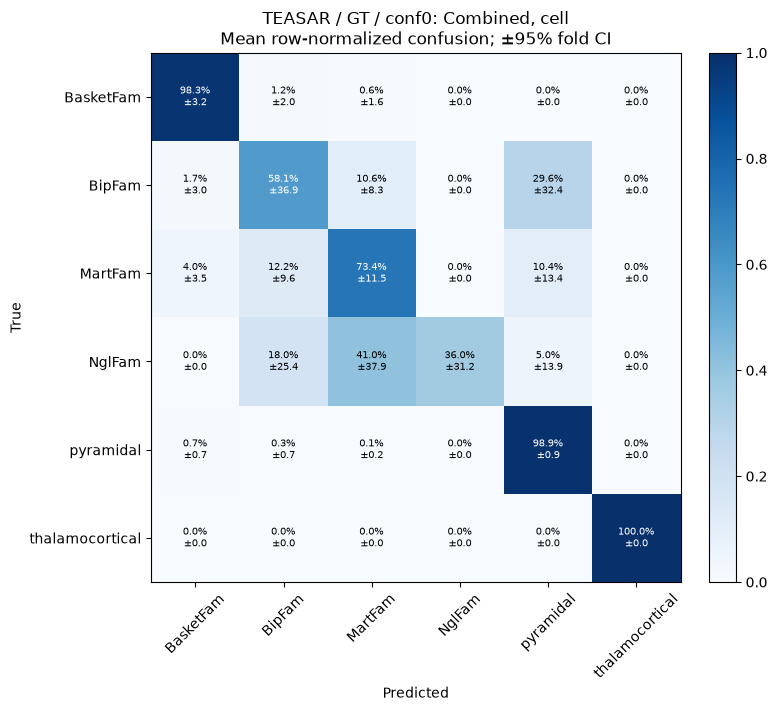

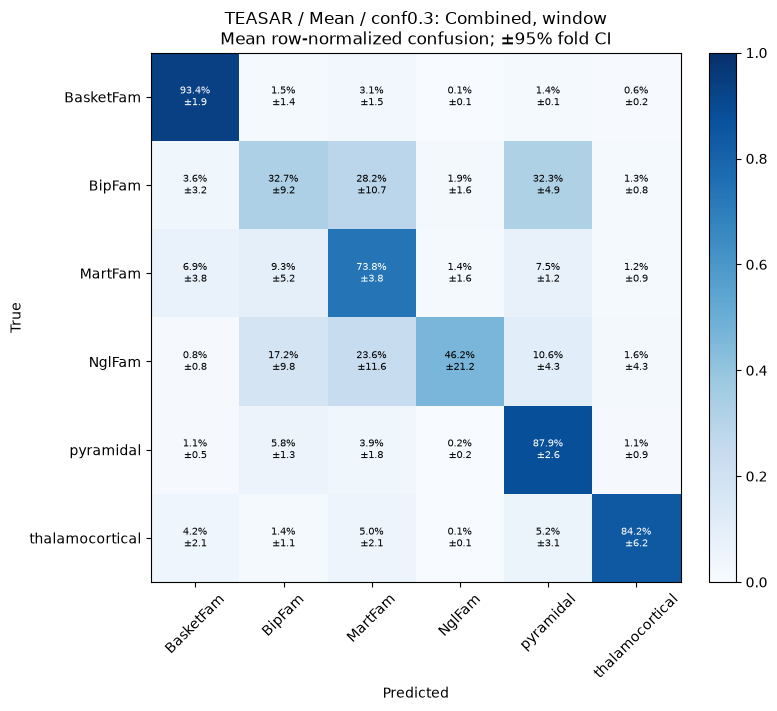

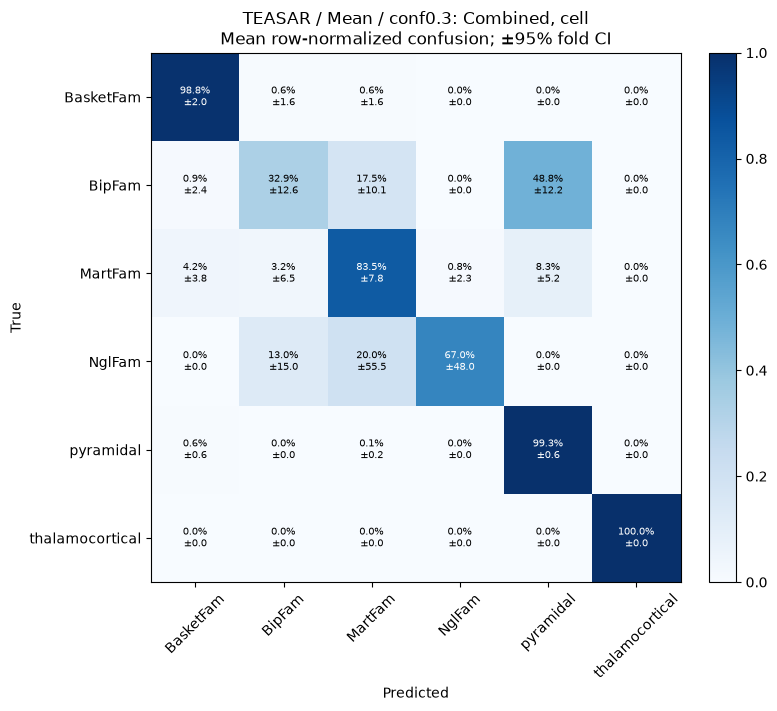

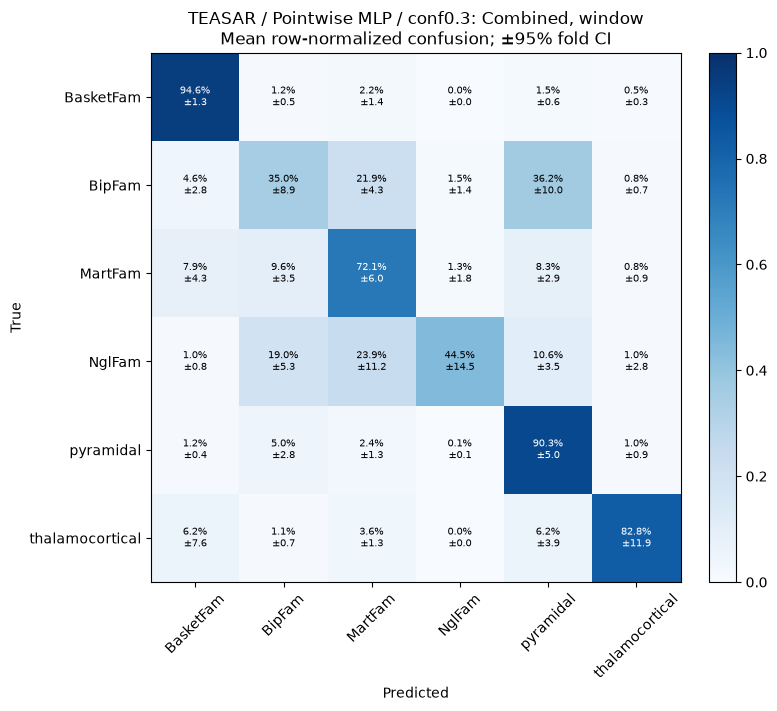

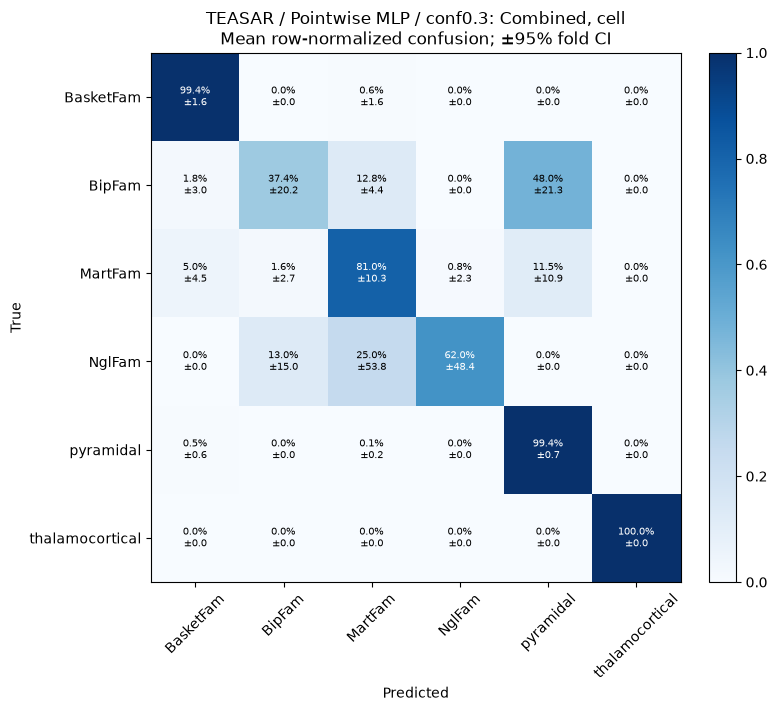

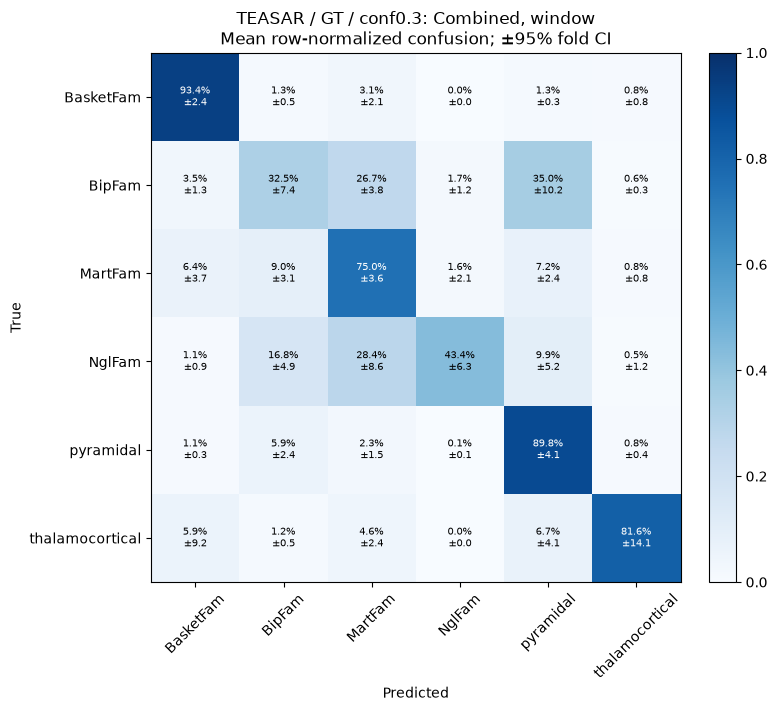

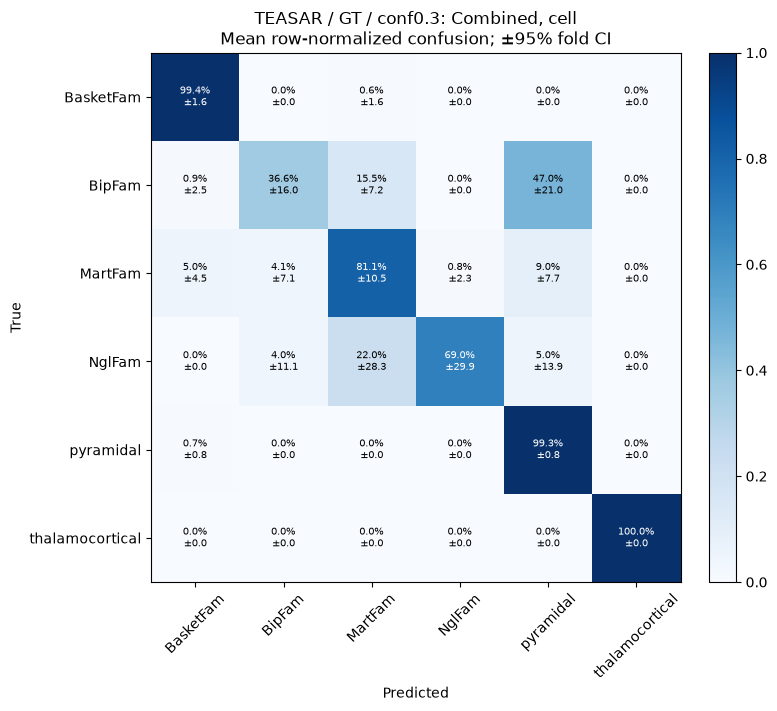

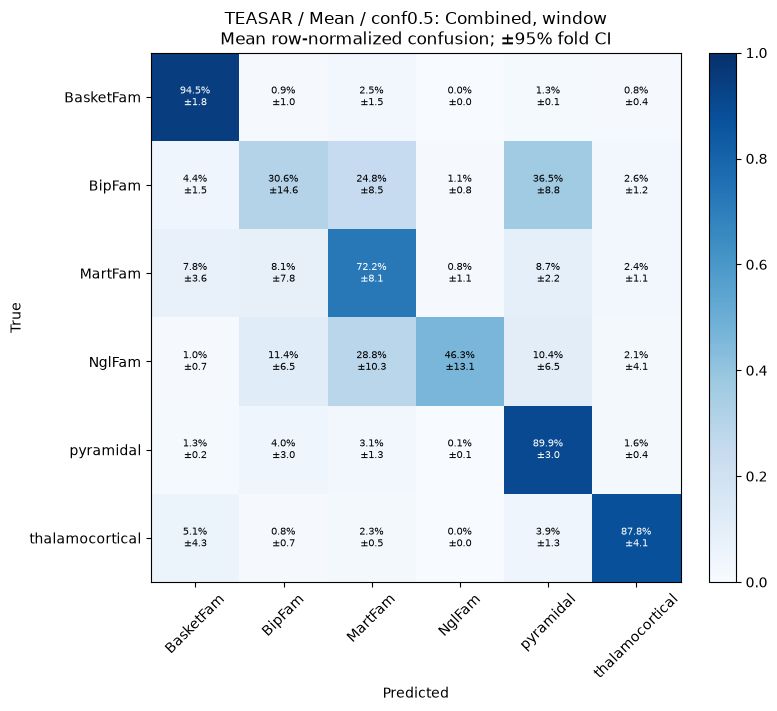

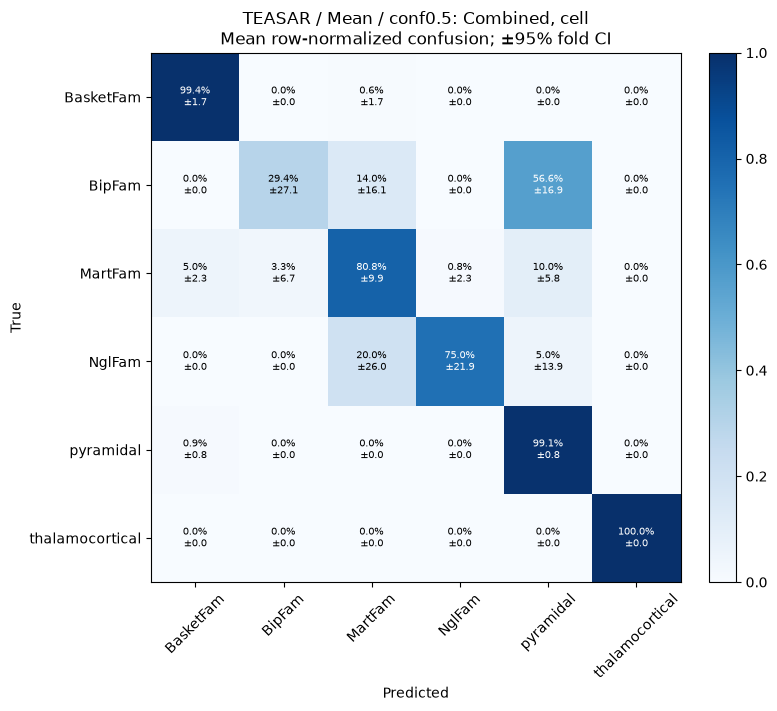

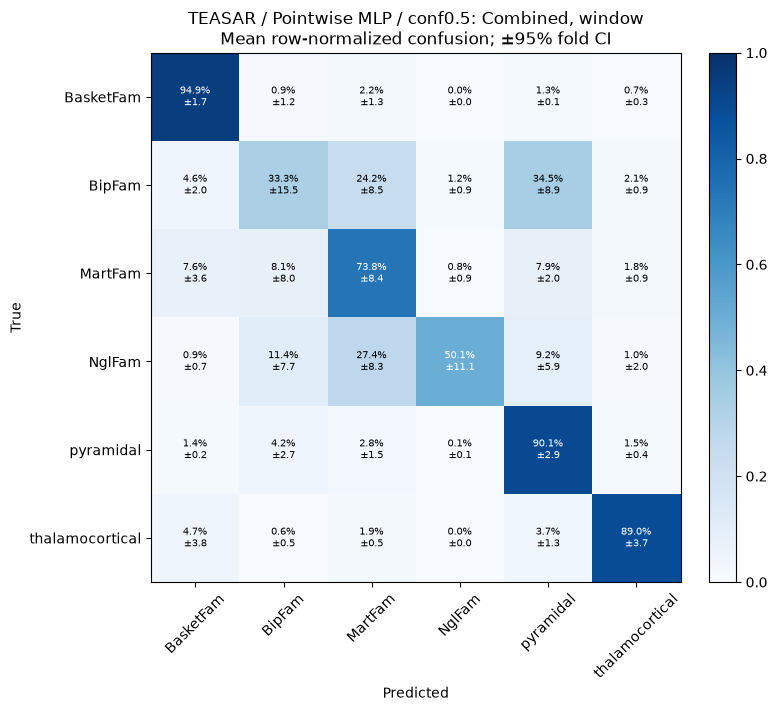

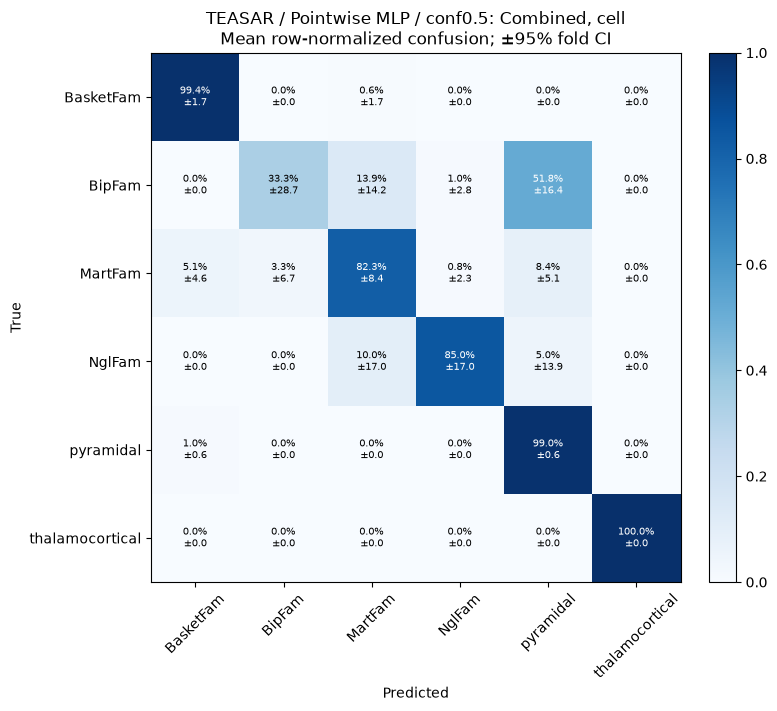

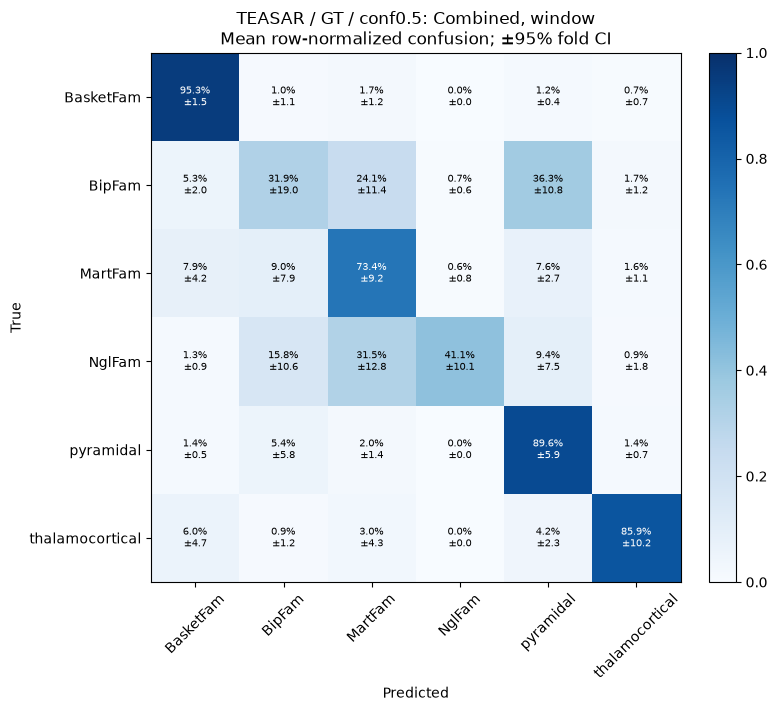

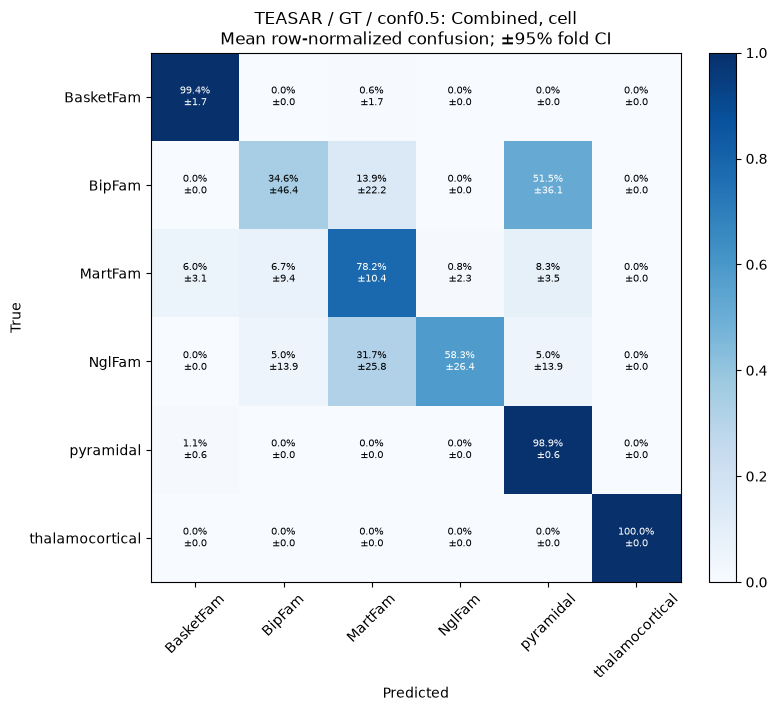

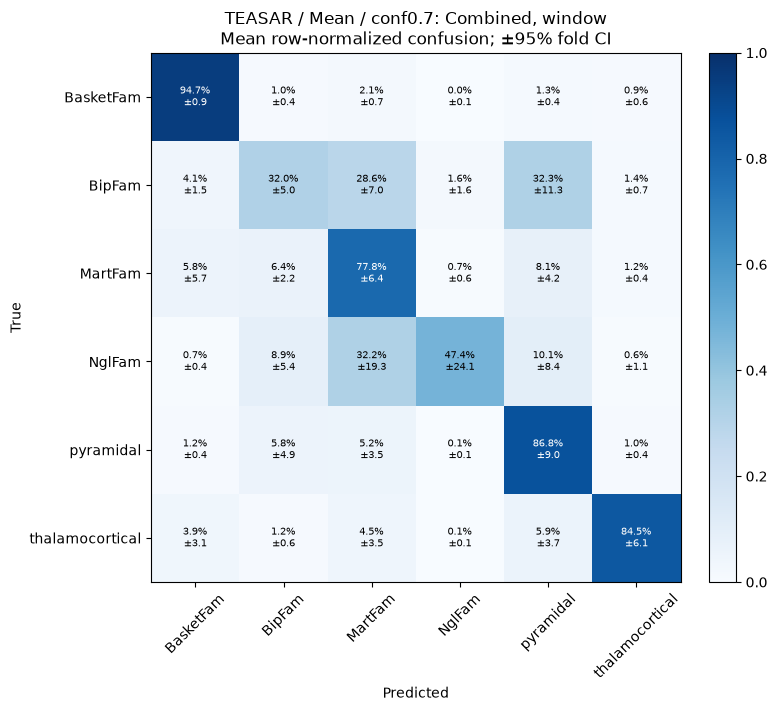

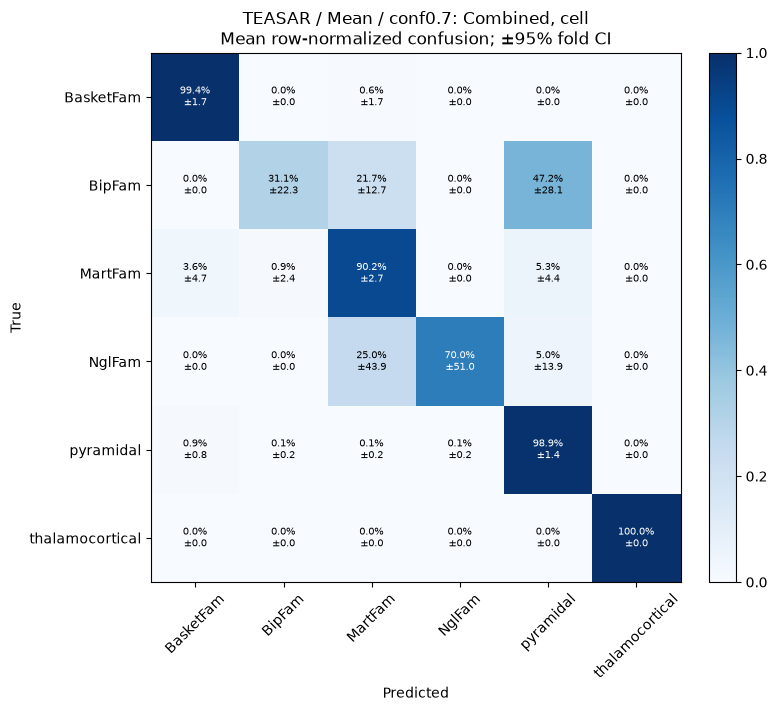

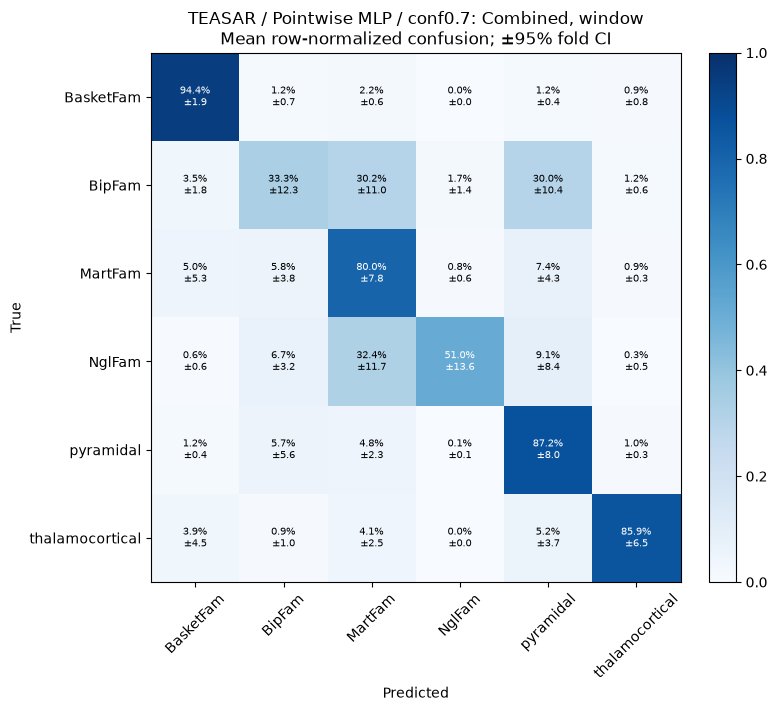

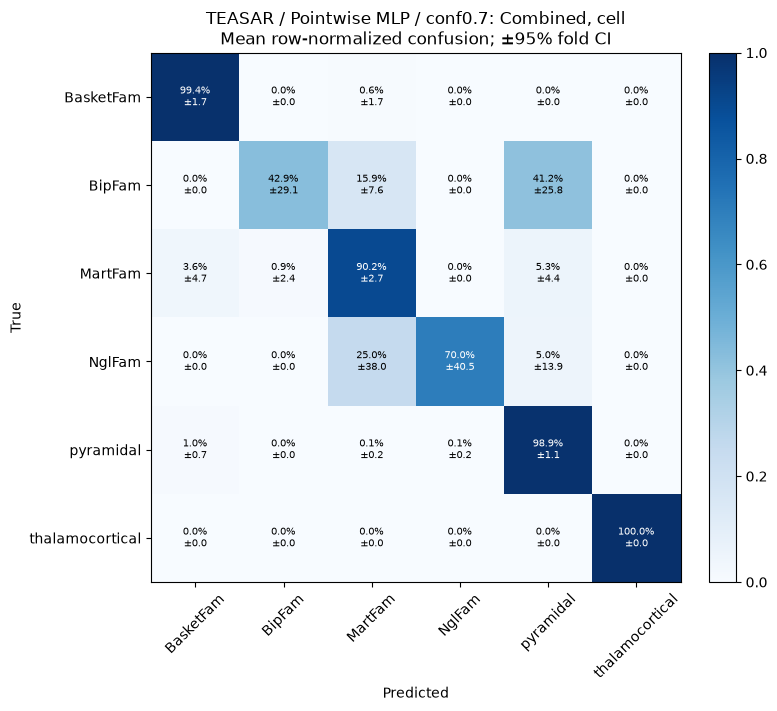

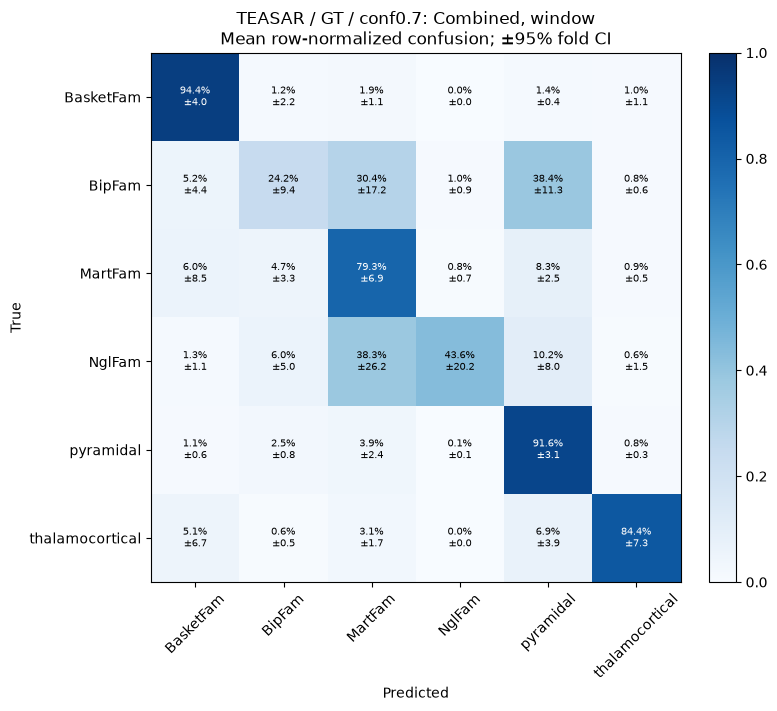

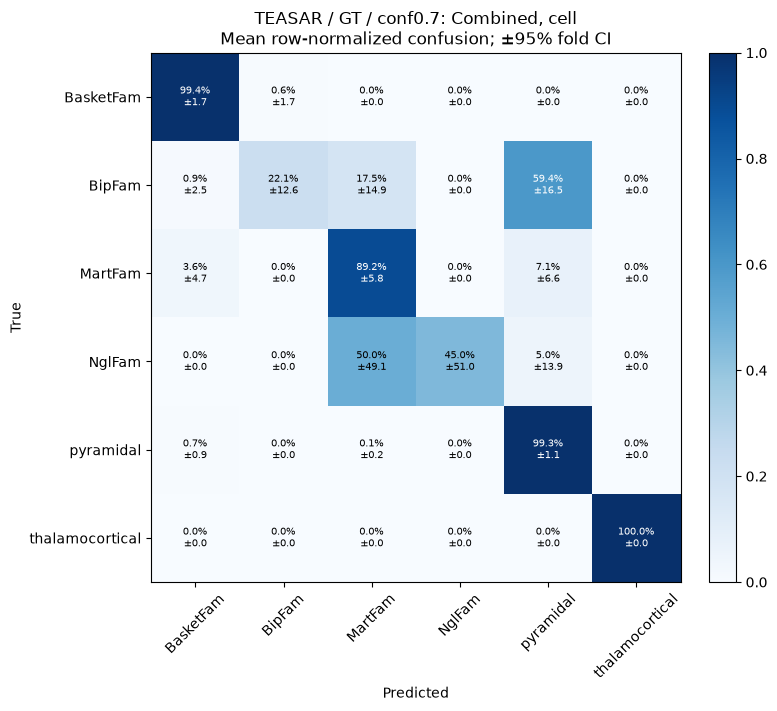

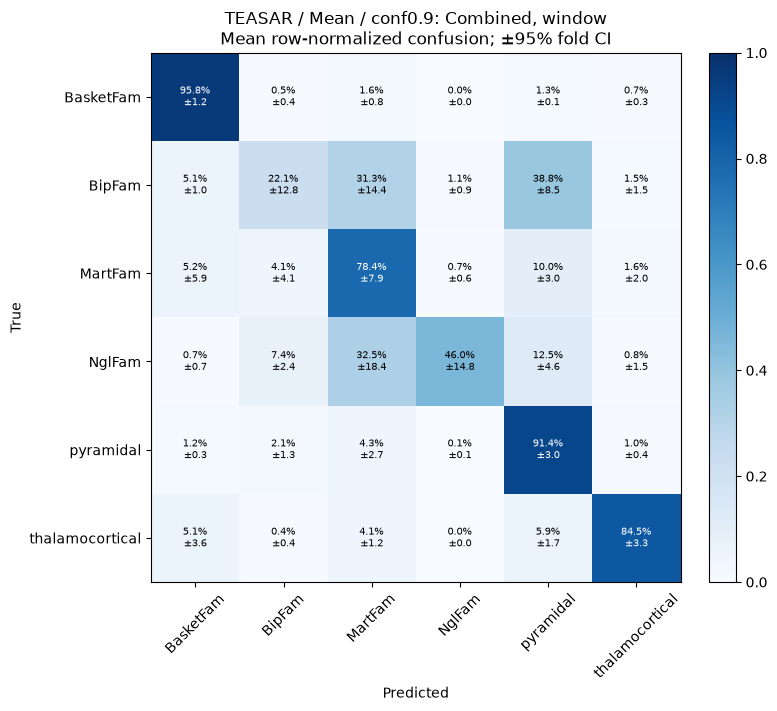

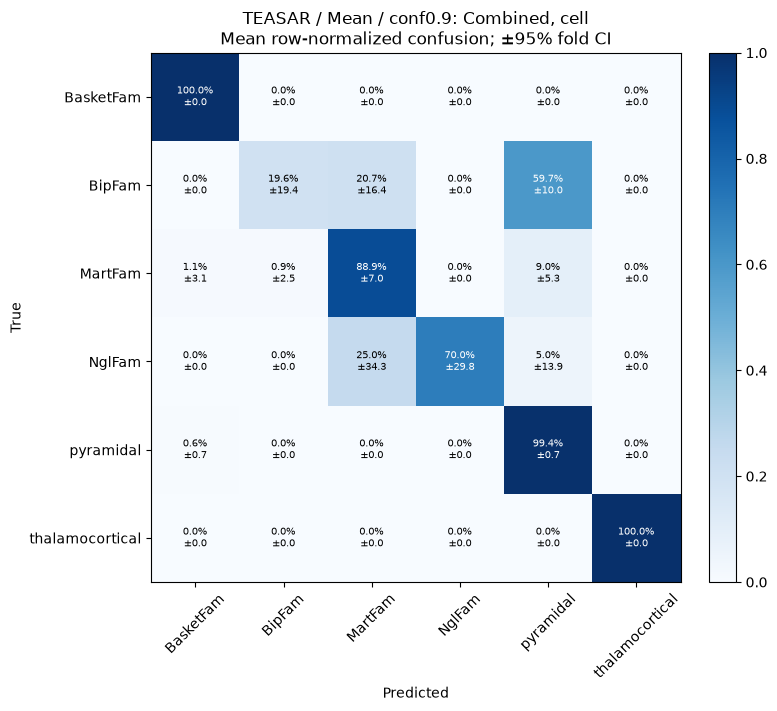

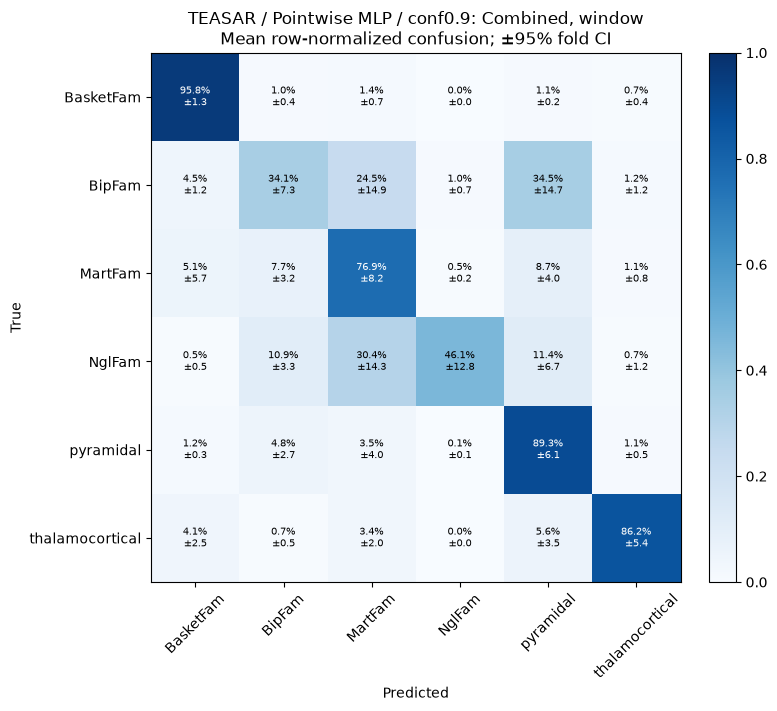

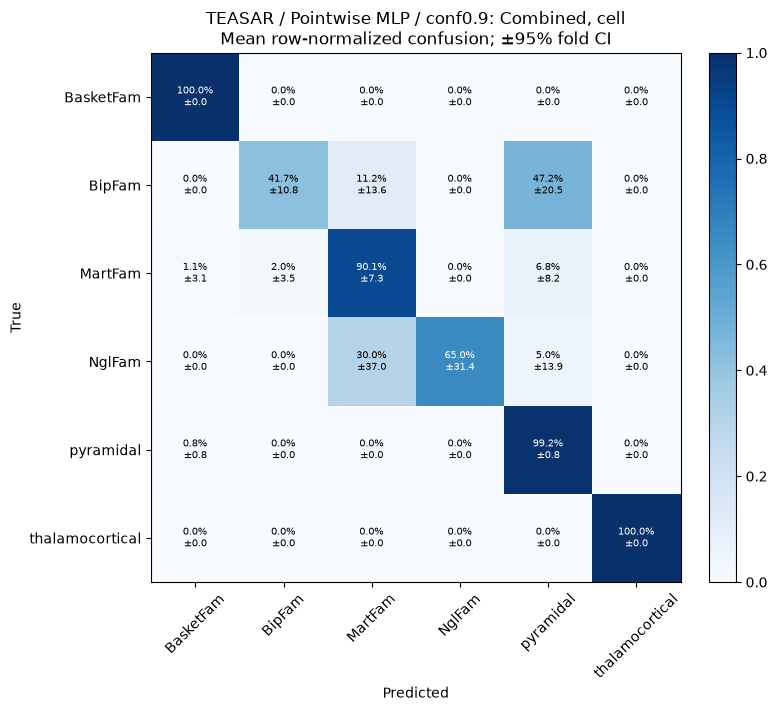

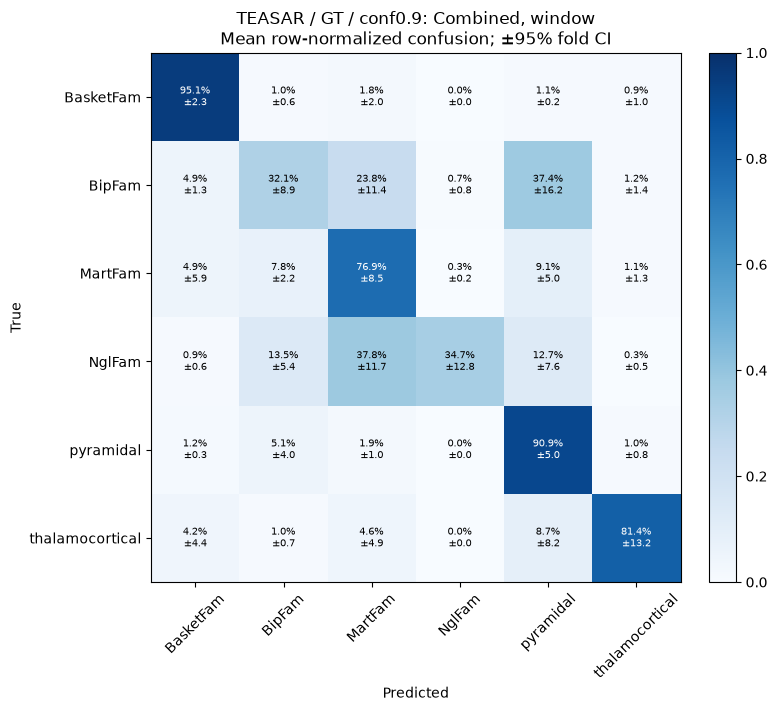

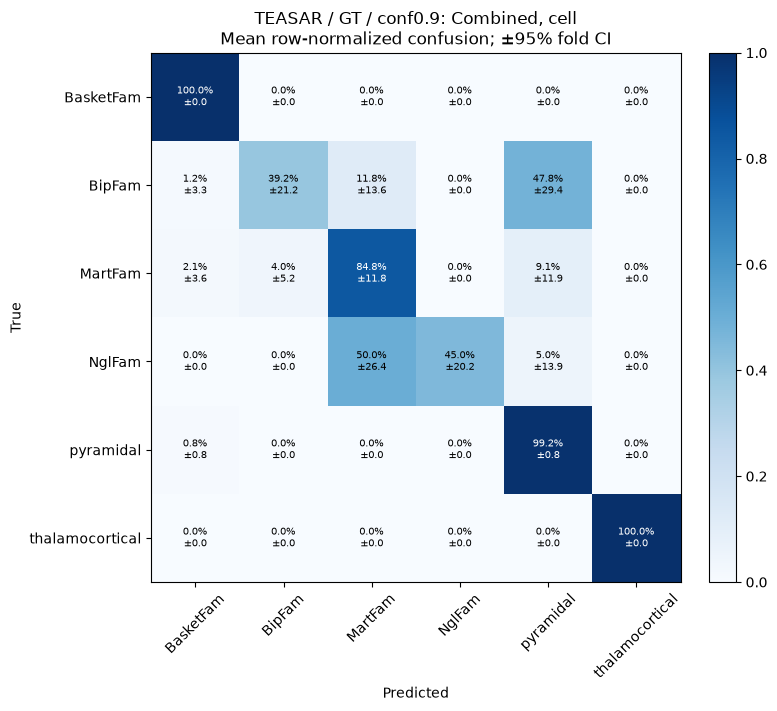

In [8]:
af.plot_confusions(cache)